# Batched small matrices

Many engineering codes apply a small matrix to a small vector, once per element: a rotation per body, a stiffness
matrix per cell. In hawk the lane space is `Grid["batch", "i":3, "j":3]`, one lane per matrix entry, and
`hawk.sum(..., over="j")` adds up the row. NumPy's `einsum` checks every answer.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [Across lanes](../across_lanes)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import plot_style, show
plot_style()

## A batch of rotations

Each batch element has a 3x3 rotation matrix `A` (a turn about z, then a tilt about x) and a vector `x`. We want
`y = A x` for every element. The batch is one extent, set once: a few hundred matrices on a CPU, many more on a GPU.

In [3]:
from nb_helpers import gpu_available
import numpy as np

B = 400 if not gpu_available() else 400_000        # batch elements: small on a CPU, large on a GPU
N = 3

def rotations(turn, tilt):
    c, s, ct, st = np.cos(turn), np.sin(turn), np.cos(tilt), np.sin(tilt)
    z, o = np.zeros_like(turn), np.ones_like(turn)
    about_z = np.stack([np.stack([c, -s, z], -1), np.stack([s, c, z], -1), np.stack([z, z, o], -1)], -2)
    about_x = np.stack([np.stack([o, z, z], -1), np.stack([z, ct, -st], -1), np.stack([z, st, ct], -1)], -2)
    return about_x @ about_z

rng = np.random.default_rng(5)
turn = np.linspace(0.0, 2 * np.pi, B, endpoint=False)
A = rotations(turn, rng.uniform(0.0, 0.5, size=B))     # (batch, i, j)
x = rng.normal(size=(B, N))                            # (batch, j)
print(A.shape, x.shape)

(400000, 3, 3) (400000, 3)


## The kernel

Three things to read in the kernel:

- `lane: Grid["batch", "i":N, "j":N]` makes one lane per `(batch, i, j)`. The last axis is the fastest, so the
  entries of a row are neighbouring lanes. `batch` is a bare label: you give its extent by name when you run.
- `A.at(lane.flat)` reads this lane's matrix entry: the lane order `(batch, i, j)` is the memory order of `A`, so the
  flat lane number is the flat index. `x.at(lane.batch * N + lane.j)` reads the vector entry it multiplies. The
  tables are flat, so nothing fixes the batch size in the kernel.
- `hawk.sum(terms, over="j")` adds the three products of a row and keeps the other axes, so the result is shaped
  `(batch, i)`.

In [4]:
import eagle
import hawk
from hawk import Grid, Scalar, Table

@hawk.kernel
def matvec(lane: Grid["batch", "i":N, "j":N], A: Table[Scalar], x: Table[Scalar]) -> Scalar:
    a = A.at(lane.flat)
    v = x.at(lane.batch * N + lane.j)
    return hawk.sum(a * v, over="j")

y = eagle.deploy(matvec).run(A=A.ravel(), x=x.ravel(), batch=B)
want = np.einsum("bij,bj->bi", A, x)
assert y.shape == (B, N) and np.allclose(y, want)
assert np.allclose(np.linalg.norm(y, axis=1), np.linalg.norm(x, axis=1))     # a rotation keeps the length
print("y = A x for", B, "matrices: matches einsum, lengths kept")

y = A x for 400000 matrices: matches einsum, lengths kept


## What the rotations did

Each arrow is the same starting vector `(1, 0, 0)` turned by a different element's matrix, seen from above. The
matrices are the same; only `x` differs. The tilt shortens some arrows a little in this view.


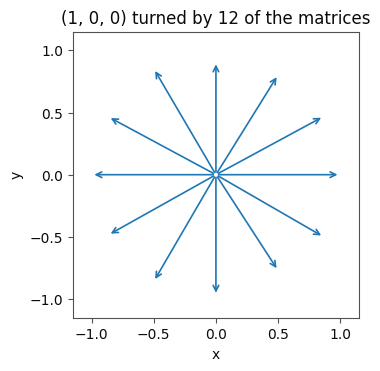
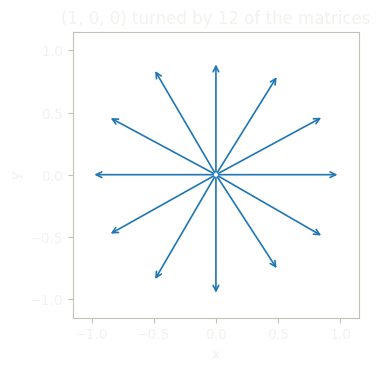

In [5]:
import matplotlib.pyplot as plt
from nb_helpers import show

e1 = np.tile([1.0, 0.0, 0.0], (B, 1))
turned = eagle.deploy(matvec).run(A=A.ravel(), x=e1.ravel(), batch=B)
pick = np.arange(12) * (B // 12)

fig, ax = plt.subplots(figsize=(3.6, 3.6), constrained_layout=True)
for k in pick:
    ax.annotate("", xy=turned[k, :2], xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=1.2, color="C0"))
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("(1, 0, 0) turned by 12 of the matrices")
show(fig, "Twelve arrows fanned around a circle seen from above, one per rotation matrix applied to the vector (1, 0, 0); the tilt shortens some")

## A sum over two axes

The energy of a displacement `x` in a cell with stiffness `K` is `x^T K x`. It needs both axes at once, so
`over=("i", "j")` folds the whole 3x3 block of lanes into one number per element. Here `K = M^T M + 0.1 I` is
symmetric and positive definite, so every energy must be positive.

In [6]:
M = rng.normal(size=(B, N, N))
K = np.swapaxes(M, 1, 2) @ M + 0.1 * np.eye(N)

@hawk.kernel
def energy(lane: Grid["batch", "i":N, "j":N], K: Table[Scalar], x: Table[Scalar]) -> Scalar:
    xi = x.at(lane.batch * N + lane.i)
    xj = x.at(lane.batch * N + lane.j)
    return hawk.sum(xi * K.at(lane.flat) * xj, over=("i", "j"))

e = eagle.deploy(energy).run(K=K.ravel(), x=x.ravel(), batch=B)
assert e.shape == (B,) and np.allclose(e, np.einsum("bi,bij,bj->b", x, K, x)) and (e > 0).all()
print("x^T K x for", B, "elements: matches einsum, all positive")

x^T K x for 400000 elements: matches einsum, all positive


## Two ways to write it: which when

**In-lane `Matrix[3, 3]`** (below): one lane owns the whole matrix. Use it for small matrices, especially when you chain
operations per element (`A @ x`, then a norm, then more). The element lives in registers and no lane waits on another.
The data goes in as planes, `(entries, lanes)`, so a `(batch, 3, 3)` array needs `A.reshape(B, 9).T`.

**`Grid` and `hawk.sum(over=...)`** (above): use it for einsum-shaped work that folds some axes and keeps others, when
`n` is too big for one lane, or when the batch is too small to fill the device and the entries supply the
parallelism. It reads the natural `(batch, i, j)` array as it is. A sum `over=` an axis ends the kernel: its result is
returned or stored, and cannot be read back in the same body. (A total over every lane can be read back; that kernel
runs in two stages.)

In [7]:
from hawk import Matrix, Vector

@hawk.kernel
def matvec_in_lane(A: Matrix[3, 3], x: Vector[3]) -> Vector[3]:
    return A @ x

planes = eagle.deploy(matvec_in_lane).run(A=A.reshape(B, 9).T, x=x.T)       # planes are (entries, lanes)
assert np.allclose(planes.T, want)
print("the in-lane form gives the same y")

the in-lane form gives the same y


## What just happened

- `Grid["batch", "i":3, "j":3]` is a three-axis lane space: one lane per matrix entry, with `batch` set by name.
- Flat `Table[Scalar]` planes hold the matrices and vectors; `.at(lane.flat)` and `.at(lane.batch * N + lane.j)` read them, so
  the batch size is set at run time. The matrix size (3x3) is fixed when the kernel is built: no ragged sizes.
- `hawk.sum(..., over="j")` is a matrix-vector product, and `over=("i", "j")` a quadratic form. Both agree with `einsum`.
- A `Matrix[3, 3]` plane is the other spelling, for a lane that owns its matrix.
- The same cells run on a CPU and a GPU; only `B` changed.

Hawk is for the small per-element algebra. For one large dense product or a solver, keep the arrays and hand them to
NumPy, PyTorch or JAX without a copy: [interop](../interop).